[   0.0s] ♻️ Modelos ya cargados, se reutilizan (unsloth/Qwen2.5-7B-Instruct-bnb-4bit)
📂 Selecciona la imagen del manga a traducir...


Saving SSP_106.webp to SSP_106.webp
[   7.9s] Imagen: 1280x1780
[   7.9s] Detectando burbujas con YOLO...
[   8.1s] ✅ Burbujas detectadas: 4
[   8.1s] OCR de 4 burbujas...
[   8.3s] OCR 1/4 → 「孕めっ！！♥」
[   9.1s] OCR 2/4 → あぁぁ、すげ．．．イクのくまんね。おほったきんね～．．あほっちゃった子宮の中．．．わざれるの・やぁ
[   9.9s] OCR 3/4 → （あぁ♡わかる．．．♡優秀遺伝子さまがワタシのドスケベ雑魚恥子をしぶちぬいてるのが．．．
[  10.5s] OCR 4/4 → （コレ．．．絶対孕むぅルイス様のアルファオス遺伝子で受精してるぅぅ♥）
[  10.5s] Traduciendo 4 burbujas en 1 lote(s)...
[  10.5s] Lote 1/1 (4 burbujas)...
[  10.5s] Corrigiendo errores de OCR...
[  31.2s] 🔧 #2 OCR corregido: あぁぁ、すごい…イクのくまんね。おほったきんね～…あほっちゃった子宮の中…わざれるの・やぁ
[  31.2s] Traduciendo...
[  48.8s] #1 「孕めっ！！♥」  →  ¡Embarazada!! ♥
[  48.8s] #2 あぁぁ、すごい…イクのくまんね。おほったきんね～…あほっちゃった子宮の中…わざれるの・やぁ  →  Ah, ¡es increíble... no creí que llegaría hasta ahí. ¡Oh, oh, oh... mi útero... está siendo penetrado por... ¡oh!
[  48.8s] #3 （あぁ♡わかる．．．♡優秀遺伝子さまがワタシのドスケベ雑魚恥子をしぶちぬいてるのが．．．  →  (Ah, ♡ entiendo... ♡ El excelente gen dominante está penetrando a mi lasciva y vulgar zanahoria vergon

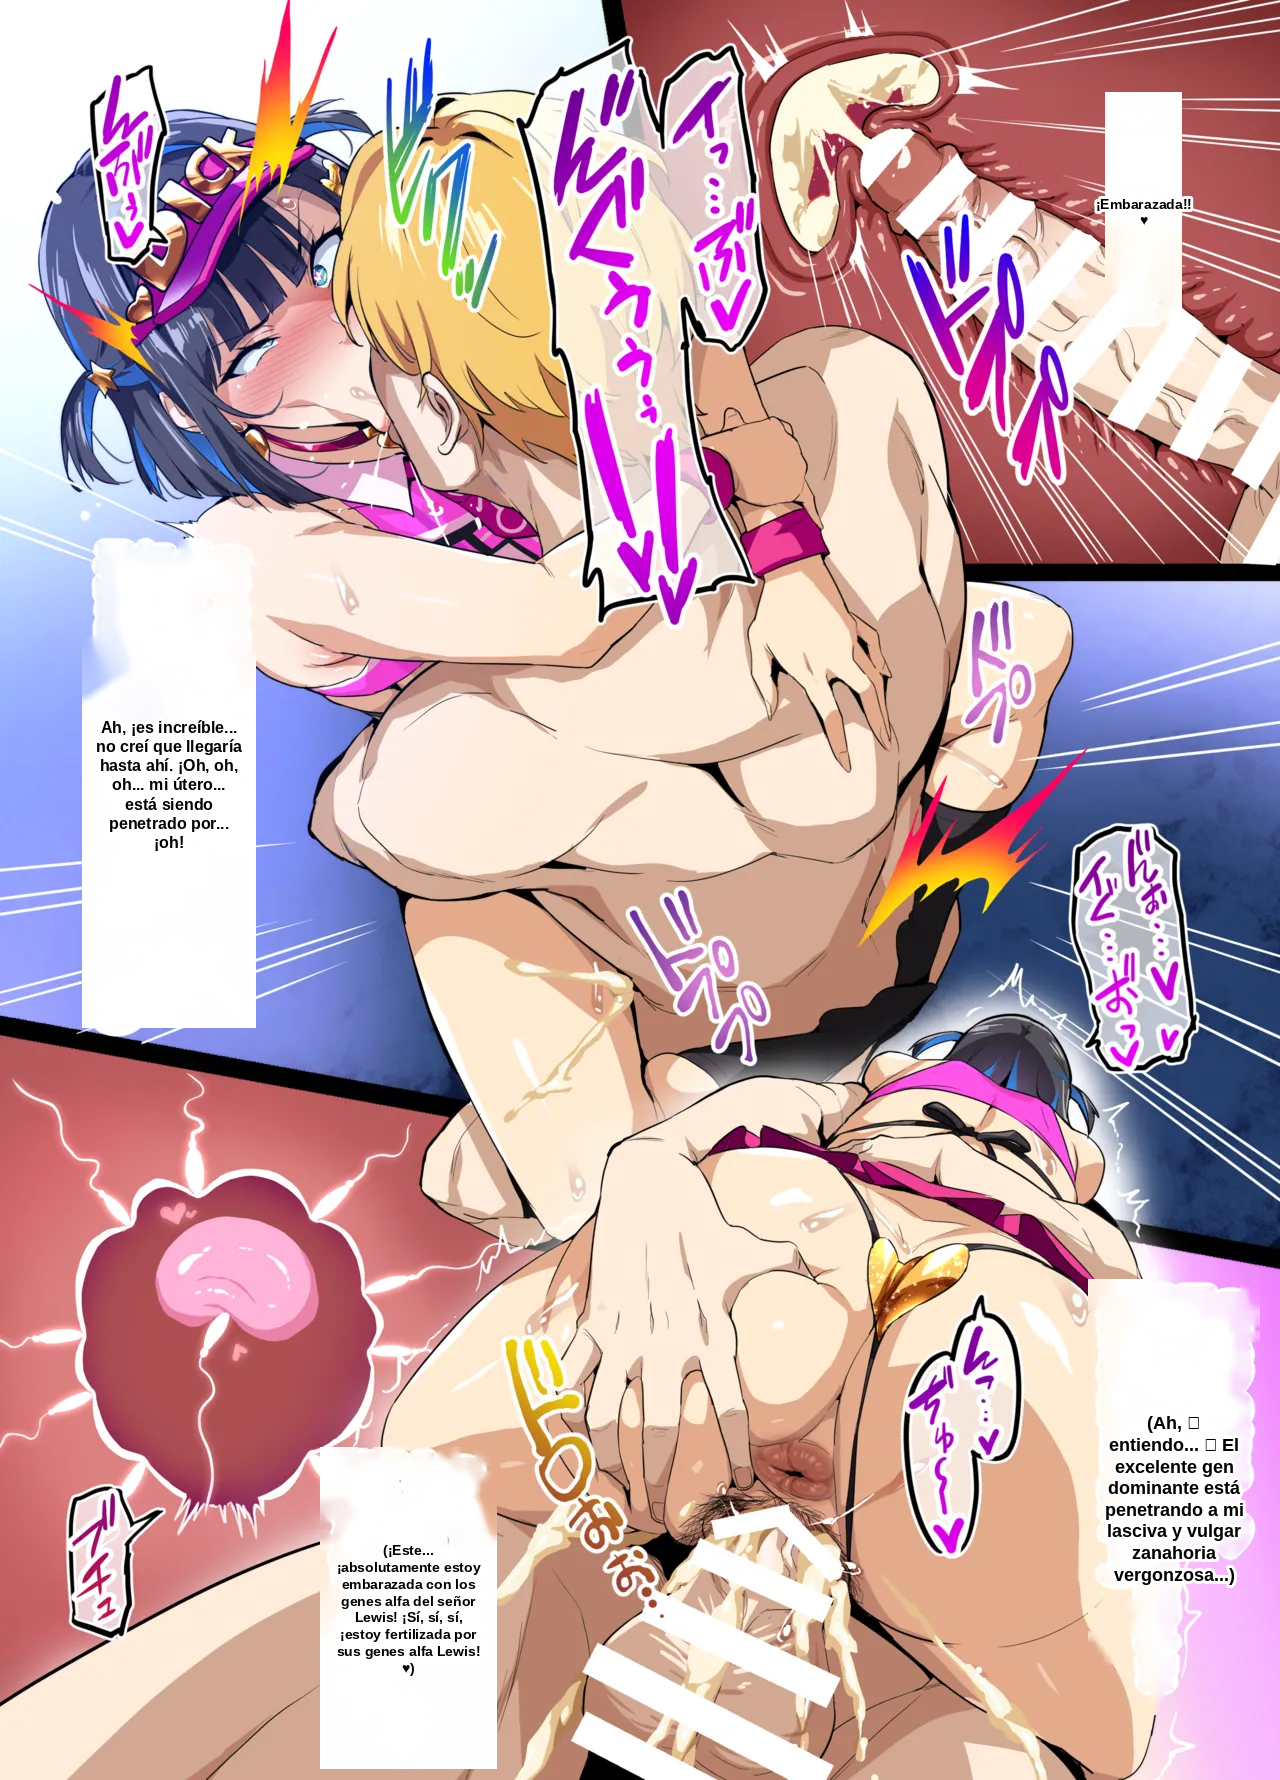

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[  50.5s] ✅ Listo → traducido_final.jpg


In [ ]:
# ============================================================
# MANGA TRANSLATOR - YOLO + MangaOCR + TRADUCTOR LLM (Qwen2.5)
# UNA SOLA CELDA. Requiere GPU: Runtime > Change runtime type > T4 GPU
# Re-ejecuta la misma celda para cada página: modelos ya cargados, solo pide la imagen.
# ============================================================
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "manga-ocr", "ultralytics", "transformers", "accelerate",
                "bitsandbytes", "sentencepiece"],
               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

import os, re, warnings, urllib.request, time
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "0"   # muestra barras de descarga
os.environ["TOKENIZERS_PARALLELISM"] = "false"
warnings.filterwarnings("ignore")

T0 = time.time()
def log(msg):
    print(f"[{time.time()-T0:6.1f}s] {msg}", flush=True)

import cv2
import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFont
from ultralytics import YOLO
from manga_ocr import MangaOcr
from loguru import logger
from google.colab.patches import cv2_imshow
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from transformers.utils import logging as hf_logging

logger.remove()
hf_logging.set_verbosity_error()

# ─────────────────────────────────────────────
# CONFIGURACIÓN
# ─────────────────────────────────────────────
# Detector de burbujas: se descarga solo (Apache-2.0, ~52 MB), no subas nada
YOLO_REPO = "ogkalu/comic-speech-bubble-detector-yolov8m"
YOLO_FILE = "comic-speech-bubble-detector.pt"

# Modelo traductor. Opciones:
#   "unsloth/Qwen2.5-7B-Instruct-bnb-4bit" -> 7B YA cuantizado: pesa ~5.5 GB, NO revienta la RAM [por defecto]
#   "Qwen/Qwen2.5-3B-Instruct"             -> más rápido, pero entiende peor el japonés
#   "Qwen/Qwen2.5-7B-Instruct"             -> original (15 GB): revienta la RAM gratis de Colab
MODELO_LLM = "unsloth/Qwen2.5-7B-Instruct-bnb-4bit"
USAR_4BIT  = False     # solo aplica a modelos NO cuantizados (el de arriba ya viene en 4 bits)

IDIOMA_DESTINO = "español latinoamericano neutro"

# Glosario opcional: nombres propios / términos que SIEMPRE deben traducirse así
GLOSARIO = {
    "お見合い": "omiai (cita arreglada con fines de matrimonio)",
    "路頭に迷う": "quedar en la calle / desamparado",
    "苦渋の決断": "decisión muy dolorosa",
    # "ナルト": "Naruto",
    # "先輩": "senpai",
}

# Contexto breve de la obra (ayuda mucho al tono). Opcional.
CONTEXTO_OBRA = ""   # ej: "Manga shonen de acción y comedia escolar."

TAM_LOTE = 12        # burbujas por petición al LLM

# ─────────────────────────────────────────────
# 1. FUENTE
# ─────────────────────────────────────────────
def get_font_path():
    for p in ["/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
              "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf",
              "DejaVuSans-Bold.ttf"]:
        if os.path.exists(p):
            return p
    try:
        urllib.request.urlretrieve(
            "https://github.com/dejavu-fonts/dejavu-fonts/raw/master/ttf/DejaVuSans-Bold.ttf",
            "DejaVuSans-Bold.ttf")
        return "DejaVuSans-Bold.ttf"
    except Exception:
        return None

FONT_PATH = get_font_path()

# ─────────────────────────────────────────────
# 2. MODELOS
# ─────────────────────────────────────────────
_CONFIG_LLM = (MODELO_LLM, USAR_4BIT)
if "llm" in globals() and globals().get("MODELO_CARGADO") != _CONFIG_LLM:
    log(f"🔄 Cambió el modelo ({globals().get('MODELO_CARGADO')} → {_CONFIG_LLM}), liberando el anterior...")
    import gc
    del llm
    gc.collect()
    torch.cuda.empty_cache()

if "llm" not in globals():      # carga la 1ª vez o cuando cambias el modelo
    log("Cargando YOLO...")
    from huggingface_hub import hf_hub_download
    modelo_yolo = YOLO(hf_hub_download(YOLO_REPO, YOLO_FILE))
    log("✅ YOLO listo")

    log("Cargando MangaOCR...")
    mocr = MangaOcr()
    log("✅ MangaOCR listo")

    DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
    log(f"Dispositivo: {DISPOSITIVO.upper()}")
    if DISPOSITIVO == "cpu":
        log("⚠️ Sin GPU: el LLM será MUY lento. Activa una T4 y reinicia.")

    log(f"Cargando tokenizer de {MODELO_LLM}...")
    tok = AutoTokenizer.from_pretrained(MODELO_LLM)
    log("✅ Tokenizer listo")

    log("Descargando/cargando el LLM (verás la barra de descarga)...")
    if "bnb-4bit" in MODELO_LLM and DISPOSITIVO == "cuda":
        # Checkpoint ya cuantizado: se carga directo, sin pasar por la RAM
        llm = AutoModelForCausalLM.from_pretrained(
            MODELO_LLM, device_map="auto", torch_dtype=torch.float16,
            low_cpu_mem_usage=True)
    elif DISPOSITIVO == "cuda" and USAR_4BIT:
        llm = AutoModelForCausalLM.from_pretrained(
            MODELO_LLM,
            quantization_config=BitsAndBytesConfig(
                load_in_4bit=True, bnb_4bit_quant_type="nf4",
                bnb_4bit_compute_dtype=torch.float16,
                bnb_4bit_use_double_quant=True),
            device_map="auto")
    else:
        llm = AutoModelForCausalLM.from_pretrained(
            MODELO_LLM,
            torch_dtype=torch.float16 if DISPOSITIVO == "cuda" else torch.float32,
            device_map="auto" if DISPOSITIVO == "cuda" else None)
    llm.eval()
    MODELO_CARGADO = _CONFIG_LLM
    log(f"✅ LLM listo: {MODELO_LLM}\n")
else:
    log(f"♻️ Modelos ya cargados, se reutilizan ({MODELO_CARGADO[0]})")

# ─────────────────────────────────────────────
# 3. TRADUCTOR ROBUSTO (con contexto de toda la página)
# ─────────────────────────────────────────────
def construir_system():
    glos = ""
    if GLOSARIO:
        glos = "\nGlosario obligatorio:\n" + "\n".join(f"- {k} = {v}" for k, v in GLOSARIO.items())
    ctx = f"\nContexto de la obra: {CONTEXTO_OBRA}" if CONTEXTO_OBRA else ""
    return (
        f"Eres un traductor profesional de manga del japonés al {IDIOMA_DESTINO}.\n"
        "Recibirás líneas numeradas, cada una es una burbuja de diálogo en orden de lectura. "
        "El texto viene de un OCR y puede tener errores: corrígelos usando el contexto.\n"
        "Reglas:\n"
        "- Traduce el SENTIDO natural y coloquial, no palabra por palabra.\n"
        "- Mantén el tono del personaje (formal, rudo, infantil, etc.) y las emociones.\n"
        "- Usa el contexto de las burbujas vecinas para sujetos omitidos y referencias.\n"
        "- Respuestas cortas: cada burbuja es pequeña, sé conciso.\n"
        "- Las onomatopeyas tradúcelas a un equivalente corto en español (ej: ドン = ¡Pum!).\n"
        "- Si una burbuja tiene varias frases entre 「」, son HABLANTES DISTINTOS: tradúcelas separadas con ' / '.\n"
        "- Traduce los modismos por su sentido, nunca literal (ej: 条件を飲む = aceptar una condición; "
        "千人近く = casi mil, no 'más de mil').\n"
        "- Mantén los honoríficos y apellidos como romaji (ej: 草司様 = señor Souji). "
        "NUNCA inventes ni cambies un nombre; si el OCR lo escribe distinto en varias líneas, "
        "es la misma persona: usa un solo nombre.\n"
        "- Usa los mismos términos en toda la página para el mismo concepto.\n"
        "- No expliques nada ni agregues notas.\n"
        "- Responde SOLO con el mismo número de líneas, con el formato exacto:\n"
        "  1: traducción\n  2: traducción"
        f"{ctx}{glos}"
    )

SYSTEM_PROMPT = construir_system()

def _generar(mensajes, max_new_tokens):
    texto = tok.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    inputs = tok(texto, return_tensors="pt").to(llm.device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens,
                           do_sample=False, repetition_penalty=1.05)
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def _parsear(respuesta, n):
    res = {}
    for m in re.finditer(r"^\s*(\d+)\s*[:：\.\)]\s*(.+?)\s*$", respuesta, flags=re.M):
        k = int(m.group(1))
        if 1 <= k <= n and k not in res:
            res[k] = m.group(2).strip().strip('"“”')
    return res

def corregir_ocr(textos):
    """Paso 1: corrige errores típicos de OCR (kanji parecidos, nombres) SIN traducir."""
    n = len(textos)
    system = (
        "Eres corrector de OCR de manga japonés. Recibes líneas numeradas que pueden tener errores "
        "de OCR: kanji parecidos confundidos, nombres leídos distinto en cada línea, símbolos raros. "
        "Corrige usando el contexto de todas las líneas (ej: お見占い→お見合い, 音波の決断→苦渋の決断, "
        "扱ってもらった→拾ってもらった). Un mismo nombre debe escribirse igual en todas. "
        "NO traduzcas. Si no estás seguro, deja el original. "
        "Responde SOLO con el mismo número de líneas, formato:\n1: texto\n2: texto")
    lineas = "\n".join(f"{i+1}: {t}" for i, t in enumerate(textos))
    resp = _generar([{"role": "system", "content": system},
                     {"role": "user", "content": lineas}],
                    max_new_tokens=120 * n + 100)
    ok = _parsear(resp, n)
    return [ok.get(i + 1, textos[i]) for i in range(n)]

def traducir_lote(textos, previo):
    """textos: lista JP. previo: lista de (jp, es) ya traducidos, como contexto."""
    n = len(textos)
    ctx = ""
    if previo:
        ctx = "Contexto previo (YA traducido, NO lo repitas):\n" + \
              "\n".join(f"{jp} -> {es}" for jp, es in previo[-6:]) + "\n\n"
    lineas = "\n".join(f"{i+1}: {t}" for i, t in enumerate(textos))
    user = f"{ctx}Traduce estas {n} burbujas:\n{lineas}"
    resp = _generar([{"role": "system", "content": SYSTEM_PROMPT},
                     {"role": "user", "content": user}],
                    max_new_tokens=80 * n + 100)
    trad = _parsear(resp, n)

    # Reintento individual para las que falten
    for i in range(1, n + 1):
        if i not in trad:
            r = _generar([{"role": "system", "content": SYSTEM_PROMPT},
                          {"role": "user", "content": f"Traduce esta burbuja:\n1: {textos[i-1]}"}],
                         max_new_tokens=150)
            p = _parsear(r, 1)
            trad[i] = p.get(1, r.split("\n")[0].strip())
    return [trad[i + 1] for i in range(n)]

# ─────────────────────────────────────────────
# 4. CARGAR IMAGEN
# ─────────────────────────────────────────────
T0 = time.time()
from google.colab import files
print("📂 Selecciona la imagen del manga a traducir...")
subida = files.upload()
RUTA_IMAGEN = next(iter(subida))
pil_original = Image.open(RUTA_IMAGEN).convert("RGB")
img_bgr = cv2.cvtColor(np.array(pil_original), cv2.COLOR_RGB2BGR)
alto, ancho = img_bgr.shape[:2]
log(f"Imagen: {ancho}x{alto}")
log("Detectando burbujas con YOLO...")

# ─────────────────────────────────────────────
# 5. DETECTAR BURBUJAS (YOLO)
# ─────────────────────────────────────────────
res_yolo = modelo_yolo.predict(img_bgr, imgsz=1024, conf=0.25, iou=0.45, verbose=False)
cajas = []
if res_yolo and len(res_yolo[0].boxes) > 0:
    boxes = res_yolo[0].boxes.xyxy.cpu().numpy()
    confs = res_yolo[0].boxes.conf.cpu().numpy()
    for i, (box, conf) in enumerate(zip(boxes, confs)):
        x1, y1, x2, y2 = map(int, box)
        cajas.append({"id": i + 1, "x1": max(0, x1), "y1": max(0, y1),
                      "x2": min(ancho, x2), "y2": min(alto, y2),
                      "conf": float(conf), "cx": (x1 + x2) // 2, "cy": (y1 + y2) // 2})
log(f"✅ Burbujas detectadas: {len(cajas)}")

# Orden de lectura manga: filas de arriba a abajo, dentro de cada fila DERECHA → IZQUIERDA
cajas_ord = sorted(cajas, key=lambda c: c["cy"])
filas, fila_act = [], []
for c in cajas_ord:
    if not fila_act or abs(c["cy"] - fila_act[-1]["cy"]) <= 150:
        fila_act.append(c)
    else:
        filas.append(sorted(fila_act, key=lambda x: -x["cx"]))
        fila_act = [c]
if fila_act:
    filas.append(sorted(fila_act, key=lambda x: -x["cx"]))
cajas_final = [c for f in filas for c in f]
for i, c in enumerate(cajas_final):
    c["id"] = i + 1

# ─────────────────────────────────────────────
# 6. OCR (todas las burbujas primero)
# ─────────────────────────────────────────────
RUIDO = set('．。、…･ ・!！?？ー～〜')
def es_ruido(t):
    return len(t) < 2 or all(ch in RUIDO for ch in t)

log(f"OCR de {len(cajas_final)} burbujas...")
for n, c in enumerate(cajas_final, 1):
    rec = img_bgr[c["y1"]:c["y2"], c["x1"]:c["x2"]]
    jp = mocr(Image.fromarray(cv2.cvtColor(rec, cv2.COLOR_BGR2RGB))).strip()
    c["jp"] = jp
    c["valida"] = not es_ruido(jp)
    c["es"] = ""
    log(f"OCR {n}/{len(cajas_final)} → {jp}")

# ─────────────────────────────────────────────
# 7. TRADUCCIÓN POR LOTES CON CONTEXTO
# ─────────────────────────────────────────────
validas = [c for c in cajas_final if c["valida"]]
previo = []
total_lotes = (len(validas) + TAM_LOTE - 1) // TAM_LOTE
log(f"Traduciendo {len(validas)} burbujas en {total_lotes} lote(s)...")
for i in range(0, len(validas), TAM_LOTE):
    lote = validas[i:i + TAM_LOTE]
    log(f"Lote {i//TAM_LOTE + 1}/{total_lotes} ({len(lote)} burbujas)...")
    log("Corrigiendo errores de OCR...")
    corr = corregir_ocr([c["jp"] for c in lote])
    for c, t in zip(lote, corr):
        if t != c["jp"]:
            log(f"🔧 #{c['id']} OCR corregido: {t}")
            c["jp"] = t
    log("Traduciendo...")
    trads = traducir_lote([c["jp"] for c in lote], previo)
    for c, t in zip(lote, trads):
        c["es"] = t
        previo.append((c["jp"], t))
        log(f"#{c['id']} {c['jp']}  →  {t}")

# ─────────────────────────────────────────────
# 8. BORRAR TEXTO JAPONÉS
# ─────────────────────────────────────────────
def borrar_texto(img, x1, y1, x2, y2):
    rec = img[y1:y2, x1:x2].copy()
    gris = cv2.cvtColor(rec, cv2.COLOR_BGR2GRAY)
    _, mask = cv2.threshold(gris, 180, 255, cv2.THRESH_BINARY_INV)
    mask = cv2.dilate(mask, np.ones((5, 5), np.uint8), iterations=3)
    img[y1:y2, x1:x2] = cv2.inpaint(rec, mask, 9, cv2.INPAINT_TELEA)
    return img

# ─────────────────────────────────────────────
# 9. ESCRIBIR TEXTO
# ─────────────────────────────────────────────
def get_font(size):
    try:
        if FONT_PATH and os.path.exists(FONT_PATH):
            return ImageFont.truetype(FONT_PATH, size)
    except Exception:
        pass
    try:
        return ImageFont.truetype("DejaVuSans-Bold.ttf", size)
    except Exception:
        return ImageFont.load_default()

def wrap_text(draw, text, font, max_w):
    words = text.split()
    if not words:
        return [""]
    lines, cur = [], words[0]
    for w in words[1:]:
        test = f"{cur} {w}"
        if draw.textbbox((0, 0), test, font=font)[2] <= max_w:
            cur = test
        else:
            lines.append(cur)
            cur = w
    lines.append(cur)
    return lines

def escribir_texto(img_pil, texto, x1, y1, x2, y2):
    draw = ImageDraw.Draw(img_pil)
    bw, bh = x2 - x1, y2 - y1
    pad_x, pad_y = int(bw * 0.08), int(bh * 0.10)
    aw, ah = max(40, bw - 2 * pad_x), max(30, bh - 2 * pad_y)

    best_size, best_lines = None, []
    for size in range(min(60, int(ah * 0.6)), 12, -2):
        font = get_font(size)
        lines = wrap_text(draw, texto, font, aw)
        # también verificar que ninguna línea sea más ancha que el área
        if any(draw.textbbox((0, 0), l, font=font)[2] > aw for l in lines):
            continue
        total_h = len(lines) * size + (len(lines) - 1) * size * 0.2
        if total_h <= ah and len(lines) <= 8:
            best_size, best_lines = size, lines
            break
    if best_size is None:
        best_size = 14
        best_lines = wrap_text(draw, texto, get_font(14), aw)

    font = get_font(best_size)
    spacing = best_size * 0.2
    line_h = best_size + spacing
    total_h = len(best_lines) * best_size + (len(best_lines) - 1) * spacing
    start_y = y1 + pad_y + (ah - total_h) / 2
    stroke = max(3, int(best_size * 0.15))

    for i, line in enumerate(best_lines):
        bb = draw.textbbox((0, 0), line, font=font)
        cx = x1 + pad_x + (aw - (bb[2] - bb[0])) / 2
        draw.text((cx, start_y + i * line_h), line, font=font,
                  fill="black", stroke_width=stroke, stroke_fill="white")
    return img_pil

# ─────────────────────────────────────────────
# 10. APLICAR Y EXPORTAR
# ─────────────────────────────────────────────
log("Borrando texto original y escribiendo traducción...")
img_final = img_bgr.copy()
for c in cajas_final:
    if c["es"]:
        img_final = borrar_texto(img_final, c["x1"], c["y1"], c["x2"], c["y2"])

img_pil = Image.fromarray(cv2.cvtColor(img_final, cv2.COLOR_BGR2RGB))
for c in cajas_final:
    if c["es"]:
        img_pil = escribir_texto(img_pil, c["es"], c["x1"], c["y1"], c["x2"], c["y2"])

img_resultado = cv2.cvtColor(np.array(img_pil), cv2.COLOR_RGB2BGR)
cv2_imshow(img_resultado)
cv2.imwrite("traducido_final.jpg", img_resultado)

from google.colab import files
files.download("traducido_final.jpg")
log("✅ Listo → traducido_final.jpg")